# 3. Hypothesis testing on real questions

Each section follows the same steps: the question, H0 and H1, alpha, the assumption checks, the test, an effect size, and a plain-English answer. I use alpha = 0.05 throughout and decide it before looking at results.

A p-value tells me how surprising the data would be if H0 were true. It does not tell me how big or how important the effect is, so I report an effect size every time.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.power import NormalIndPower, TTestIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest

from src import SEED
from src.data import load_bank, load_bike_day
from src.plotting import INK_2, PALETTE, save, set_style
from src.stats_utils import cohens_d, cramers_v, eta_squared, rank_biserial, sample_size_two_proportions

set_style()
ALPHA = 0.05
rng = np.random.default_rng(SEED)

day = load_bike_day()
bank = load_bank()

def verdict(p):
    return f"p = {p:.3g} -> " + ("reject H0" if p < ALPHA else "fail to reject H0")

A caveat that applies to the bike tests: days are not independent (weather and season run in streaks), and the tests below assume independence. I keep that in mind when reading borderline p-values.

## Test 1. Do working days have more total rentals than weekends and holidays? (Welch t-test)

- **H0:** mean daily rentals are the same on working and non-working days.
- **H1:** the means differ (two-sided).
- **alpha:** 0.05

In [2]:
work = day.loc[day["workingday"] == 1, "cnt"]
off = day.loc[day["workingday"] == 0, "cnt"]
print(f"working days: n={len(work)}  mean={work.mean():.1f}  sd={work.std():.1f}")
print(f"non-working:  n={len(off)}  mean={off.mean():.1f}  sd={off.std():.1f}")

# assumption checks
lev = stats.levene(work, off)
print(f"Levene test for equal variance: p = {lev.pvalue:.3g}")
print(f"skew: working {work.skew():.3f}, non-working {off.skew():.3f}")

working days: n=500  mean=4584.8  sd=1878.4
non-working:  n=231  mean=4330.2  sd=2052.1
Levene test for equal variance: p = 0.0375
skew: working -0.074, non-working 0.039


Group sizes are unequal (500 vs 231), so I use Welch's t-test, which does not assume equal variances. It is the safer default and costs almost nothing when variances happen to be equal. With n in the hundreds and little skew, the CLT from notebook 2 covers the normality assumption for the means.

In [3]:
t = stats.ttest_ind(work, off, equal_var=False)
ci = t.confidence_interval(confidence_level=0.95)
d = cohens_d(work, off)
print(f"Welch t = {t.statistic:.3f}, df = {t.df:.1f}, {verdict(t.pvalue)}")
print(f"difference in means: {work.mean() - off.mean():.1f} rentals/day, 95% CI [{ci.low:.1f}, {ci.high:.1f}]")
print(f"Cohen's d = {d:.3f}")

Welch t = 1.601, df = 413.9, p = 0.11 -> fail to reject H0
difference in means: 254.7 rentals/day, 95% CI [-57.9, 567.2]
Cohen's d = 0.132


**Conclusion:** p = 0.11, so I fail to reject H0. Working days average 254.7 more rentals, but the 95% CI runs from -57.9 to 567.2 and includes zero, and Cohen's d is only 0.132. I found no evidence that total demand depends on whether it is a working day. That is not the same as proving there is no difference, which the power analysis below makes concrete.

## Test 2. Do casual riders behave differently on working days? (Mann-Whitney U)

Total rentals barely move, but the mix might. Casual (non-member) riders look like leisure users.

- **H0:** the distribution of daily casual rentals is the same on working and non-working days.
- **H1:** one group tends to have larger values (two-sided).
- **alpha:** 0.05

In [4]:
cw = day.loc[day["workingday"] == 1, "casual"]
co = day.loc[day["workingday"] == 0, "casual"]
print(f"skew: working {cw.skew():.3f}, non-working {co.skew():.3f}")
print(f"Shapiro-Wilk p (working days): {stats.shapiro(cw).pvalue:.3g}")

skew: working 0.524, non-working 0.245
Shapiro-Wilk p (working days): 6.01e-11


Casual counts are skewed and clearly not normal, so I use Mann-Whitney U, which compares ranks and does not need normality. The effect size is the rank-biserial correlation: 0 means no tendency either way, and 1 means every non-working day beats every working day.

In [5]:
mw = stats.mannwhitneyu(co, cw, alternative="two-sided")
rb = rank_biserial(mw.statistic, len(co), len(cw))
print(f"median casual: non-working {co.median():.0f}, working {cw.median():.0f}")
print(f"U = {mw.statistic:.0f}, {verdict(mw.pvalue)}")
print(f"rank-biserial r = {rb:.3f}  (P(non-working day > working day) = {(rb + 1) / 2:.3f})")

median casual: non-working 1338, working 616
U = 87496, p = 3.79e-29 -> reject H0
rank-biserial r = 0.515  (P(non-working day > working day) = 0.758)


**Conclusion:** p = 3.79e-29, so I reject H0. Casual riders are much busier on non-working days, with a median of 1,338 against 616. A random non-working day beats a random working day 75.8% of the time (rank-biserial r = 0.515, a large effect). So the totals in Test 1 hide a shift in who rides: members on working days, casual riders on days off.

## Test 3. Is subscribing related to how the client was contacted? (chi-square of independence)

- **H0:** subscription and contact type (cellular vs telephone) are independent.
- **H1:** they are associated.
- **alpha:** 0.05

In [6]:
table = pd.crosstab(bank["contact"], bank["subscribed"])
chi2, p, dof, expected = stats.chi2_contingency(table)
print(table)
print(f"smallest expected cell count: {expected.min():.0f}  (needs to be at least 5)")
print(f"chi2 = {chi2:.1f}, dof = {dof}, {verdict(p)}")
print(f"Cramer's V = {cramers_v(table):.3f}")
rates = bank.groupby("contact")["subscribed"].mean()
print(f"subscription rate: cellular {rates['cellular']:.2%}, telephone {rates['telephone']:.2%}")

subscribed      0     1
contact                
cellular    22291  3853
telephone   14257   787
smallest expected cell count: 1695  (needs to be at least 5)
chi2 = 862.3, dof = 1, p = 1.53e-189 -> reject H0
Cramer's V = 0.145
subscription rate: cellular 14.74%, telephone 5.23%


**Conclusion:** p = 1.53e-189, so I reject H0. Clients reached on a mobile phone subscribed at 14.74% against 5.23% on a landline. Cramer's V is 0.145, which looks modest, but for a 2x2 table V is capped well below 1 when one outcome is rare, so it understates how big a 9.5 point gap in rate is in business terms. This is an association. Mobile and landline clients probably differ in other ways too.

## Test 4. Does weather change daily rentals? (one-way ANOVA with post-hoc)

There are three weather levels in the daily data: clear, mist, and light rain or snow. Heavy rain never appears at the daily level.

- **H0:** mean daily rentals are equal across all three weather levels.
- **H1:** at least one level has a different mean.
- **alpha:** 0.05

In [7]:
order = ["clear", "mist", "light rain/snow"]
groups = [day.loc[day["weather"] == w, "cnt"] for w in order]
print(day.groupby("weather")["cnt"].agg(["size", "mean", "std"]).loc[order])
print(f"Levene p = {stats.levene(*groups).pvalue:.3g}")
for w, g in zip(order, groups):
    print(f"Shapiro p ({w}): {stats.shapiro(g).pvalue:.3g}")

                 size         mean          std
weather                                        
clear             463  4876.786177  1879.483989
mist              247  4035.862348  1809.109918
light rain/snow    21  1803.285714  1240.284449
Levene p = 0.0521
Shapiro p (clear): 7.9e-07
Shapiro p (mist): 0.0015
Shapiro p (light rain/snow): 0.0923


Classic ANOVA assumes equal variances and normal groups. The rainy group is small (21 days) and has a smaller spread. I run the classic F test, then Welch's ANOVA (does not assume equal variance) and Kruskal-Wallis (rank based) as checks. If all three agree, the answer does not hinge on the assumptions.

In [8]:
f = stats.f_oneway(*groups)
welch = anova_oneway(groups, use_var="unequal")
kw = stats.kruskal(*groups)
eta2 = eta_squared(groups)
print(f"classic ANOVA:  F = {f.statistic:.2f}, {verdict(f.pvalue)}")
print(f"Welch ANOVA:    F = {welch.statistic:.2f}, {verdict(welch.pvalue)}")
print(f"Kruskal-Wallis: H = {kw.statistic:.2f}, {verdict(kw.pvalue)}")
print(f"eta squared = {eta2:.3f}  (share of variance in daily rentals explained by weather)")

classic ANOVA:  F = 40.07, p = 3.11e-17 -> reject H0
Welch ANOVA:    F = 65.17, p = 1.52e-15 -> reject H0
Kruskal-Wallis: H = 67.18, p = 2.59e-15 -> reject H0
eta squared = 0.099  (share of variance in daily rentals explained by weather)


ANOVA only says that some difference exists. Tukey's HSD tells me which pairs differ while keeping the family-wise error rate at 5% across all three comparisons.

In [9]:
tukey = pairwise_tukeyhsd(day["cnt"], day["weather"], alpha=ALPHA)
print(tukey.summary())

             Multiple Comparison of Means - Tukey HSD, FWER=0.05             
     group1          group2      meandiff  p-adj   lower      upper    reject
-----------------------------------------------------------------------------
          clear light rain/snow -3073.5005   0.0 -4038.2458 -2108.7551   True
          clear            mist  -840.9238   0.0 -1181.6303  -500.2174   True
light rain/snow            mist  2232.5766   0.0  1249.6991  3215.4542   True
-----------------------------------------------------------------------------


**Conclusion:** all three tests reject H0 (classic F p = 3.11e-17, Welch p = 1.52e-15, Kruskal-Wallis p = 2.59e-15), so the answer does not hinge on the borderline Levene result or the non-normal groups. Tukey shows every pair differs: mist days average 841 fewer rentals than clear days, and light rain or snow days 3,074 fewer. Weather alone explains 9.9% of the variance in daily rentals (eta squared 0.099). One caveat: bad weather is more common in winter, so part of this gap is really season. The regression in notebook 4 separates the two.

## Power analysis: was Test 1 even able to see a small effect?

When a test does not reject H0 the next question is whether it had enough data to detect an effect I would care about. Here I ask two things: what power did Test 1 have for the effect it observed, and how many days per group would I need for 80% power?

In [10]:
power = TTestIndPower()
ratio = len(off) / len(work)
obs_power = power.power(effect_size=abs(d), nobs1=len(work), ratio=ratio, alpha=ALPHA)
n_needed = power.solve_power(effect_size=abs(d), power=0.8, ratio=1.0, alpha=ALPHA)
print(f"observed |d| = {abs(d):.3f}")
print(f"power of Test 1 to detect |d| = {abs(d):.3f}: {obs_power:.3f}")
print(f"days per group needed for 80% power at that effect size: {np.ceil(n_needed):.0f}")
for target_d in (0.2, 0.5):
    print(f"days per group for 80% power at d = {target_d}: {np.ceil(power.solve_power(target_d, power=0.8, alpha=ALPHA)):.0f}")

observed |d| = 0.132
power of Test 1 to detect |d| = 0.132: 0.379
days per group needed for 80% power at that effect size: 908
days per group for 80% power at d = 0.2: 394
days per group for 80% power at d = 0.5: 64


Test 1 had only 37.9% power to detect an effect of the size it observed. To have an 80% chance of catching d = 0.132 I would need 908 days per group, more than the dataset has in total. So the honest reading of Test 1 is "no evidence of a difference, and not enough data to rule out a small one".

## Multiple testing: screening ten features at once

A common analyst move is to test every categorical column against the target and keep the significant ones. With ten tests at alpha 0.05, the chance of at least one false positive (if every H0 were true) is 1 - 0.95^10, about 40%. Two standard fixes:

- **Bonferroni** controls the family-wise error rate. Simple and strict.
- **Benjamini-Hochberg** controls the false discovery rate, the expected share of false hits among the hits. Less strict, usually better for screening.

For each column, H0 is that it is independent of subscribing.

In [11]:
cats = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "day_of_week", "poutcome"]
rows = []
for c in cats:
    tab = pd.crosstab(bank[c], bank["subscribed"])
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    rows.append({"feature": c, "dof": dof, "chi2": chi2, "p_raw": p, "cramers_v": cramers_v(tab)})
screen = pd.DataFrame(rows)
screen["p_bonferroni"] = multipletests(screen["p_raw"], alpha=ALPHA, method="bonferroni")[1]
screen["p_bh"] = multipletests(screen["p_raw"], alpha=ALPHA, method="fdr_bh")[1]
screen["significant_raw"] = screen["p_raw"] < ALPHA
screen["significant_bh"] = screen["p_bh"] < ALPHA
screen["significant_bonferroni"] = screen["p_bonferroni"] < ALPHA
print(f"1 - 0.95^10 = {1 - 0.95 ** 10:.3f}")
screen.sort_values("p_raw").reset_index(drop=True)

1 - 0.95^10 = 0.401


,feature,dof,chi2,p_raw,cramers_v,p_bonferroni,p_bh,significant_raw,significant_bh,significant_bonferroni
0,month,9,3101.149351,0.000000e+00,0.274395,0.000000e+00,0.000000e+00,True,True,True
1,poutcome,2,4230.523798,0.000000e+00,0.320488,0.000000e+00,0.000000e+00,True,True,True
2,job,11,961.242440,4.189763e-199,0.152768,4.189763e-198,1.396588e-198,True,True,True
3,contact,1,862.318364,1.525986e-189,0.144773,1.525986e-188,3.814964e-189,True,True,True
4,default,2,406.577515,5.161958e-89,0.099354,5.161958e-88,1.032392e-88,True,True,True
5,education,7,193.105905,3.305189e-38,0.068472,3.305189e-37,5.508648e-38,True,True,True
6,marital,3,122.655152,2.068015e-26,0.054570,2.068015e-25,2.954307e-26,True,True,True
7,day_of_week,4,26.144939,2.958482e-05,0.025195,2.958482e-04,3.698103e-05,True,True,True
8,housing,2,5.684496,5.829448e-02,0.011748,5.829448e-01,6.477164e-02,False,False,False
9,loan,2,1.094028,5.786753e-01,0.005154,1.000000e+00,5.786753e-01,False,False,False


Here the corrections change nothing. Eight features pass under all three rules, and housing and loan fail all three. With 41,188 rows almost any real association clears the bar, so the effect size is the more useful filter. `day_of_week` passes easily but has a Cramer's V of 0.025, which is negligible in practice, while `poutcome` (0.320) and `month` (0.274) are strong.

To see the correction actually do its job I need a case where H0 is known to be true. So I add 20 columns of pure noise, test each against subscribing, and repeat that 500 times.

In [12]:
y_bank = bank["subscribed"].to_numpy()
n_noise, n_rounds = 20, 500
raw_hits, bh_hits, bonf_hits = [], [], []
for _ in range(n_rounds):
    noise = rng.random((n_noise, len(y_bank))) < 0.5
    pvals = []
    for col in noise:
        tab = np.array([[np.sum(~col & (y_bank == 0)), np.sum(~col & (y_bank == 1))],
                        [np.sum(col & (y_bank == 0)), np.sum(col & (y_bank == 1))]])
        pvals.append(stats.chi2_contingency(tab)[1])
    pvals = np.array(pvals)
    raw_hits.append(np.sum(pvals < ALPHA))
    bh_hits.append(multipletests(pvals, alpha=ALPHA, method="fdr_bh")[0].sum())
    bonf_hits.append(multipletests(pvals, alpha=ALPHA, method="bonferroni")[0].sum())
noise_summary = pd.DataFrame({
    "rule": ["raw p < 0.05", "Benjamini-Hochberg", "Bonferroni"],
    "avg false hits per 20 tests": [np.mean(raw_hits), np.mean(bh_hits), np.mean(bonf_hits)],
    "share of rounds with any false hit": [np.mean(np.array(raw_hits) > 0), np.mean(np.array(bh_hits) > 0), np.mean(np.array(bonf_hits) > 0)],
})
noise_summary

,rule,avg false hits per 20 tests,share of rounds with any false hit
0,raw p < 0.05,0.992,0.646
1,Benjamini-Hochberg,0.064,0.058
2,Bonferroni,0.058,0.056


With no correction, a typical round flags about one noise column (0.992 on average), and 64.6% of rounds flag at least one. That matches the 1 - 0.95^20 = 64% from theory. Both corrections bring the share of rounds with any false hit down to about 5% (5.8% for Benjamini-Hochberg, 5.6% for Bonferroni). When there are many real effects mixed in, BH keeps more of them than Bonferroni does, which is why I would use it for feature screening.

## A/B test, simulated, with sample-size planning

Suppose the bank wants to try a new call script. The current conversion rate is the observed 11.27%. They would care about a lift to 12.77% (1.5 percentage points). Before running anything I plan the sample size.

- **H0:** the new script converts at the same rate as the old one.
- **H1:** the rates differ (two-sided).
- **alpha:** 0.05, **power:** 0.80

In [13]:
p_a = bank["subscribed"].mean()
p_b = p_a + 0.015
n_formula = sample_size_two_proportions(p_a, p_b, alpha=ALPHA, power=0.8)
h = proportion_effectsize(p_b, p_a)
n_sm = NormalIndPower().solve_power(effect_size=h, alpha=ALPHA, power=0.8, ratio=1.0)
print(f"baseline {p_a:.4f}, target {p_b:.4f}")
print(f"per-arm n, classic formula (src.stats_utils): {n_formula:,}")
print(f"per-arm n, statsmodels arcsine method:      {np.ceil(n_sm):,.0f}")

baseline 0.1127, target 0.1277
per-arm n, classic formula (src.stats_utils): 7,375
per-arm n, statsmodels arcsine method:      7,369


Both methods land within a few calls of each other. I round up to the larger one and simulate the experiment many times, once where the script truly does nothing and once where it truly lifts conversion by 1.5 points. If the plan is right, the first should reject about 5% of the time and the second about 80%.

In [14]:
n_arm = int(max(n_formula, np.ceil(n_sm)))
sims = 5_000

def run_ab(p_control, p_treat):
    a = rng.binomial(n_arm, p_control, size=sims)
    b = rng.binomial(n_arm, p_treat, size=sims)
    pvals = np.array([proportions_ztest([bi, ai], [n_arm, n_arm])[1] for ai, bi in zip(a, b)])
    return pvals

p_null = run_ab(p_a, p_a)
p_alt = run_ab(p_a, p_b)
print(f"n per arm = {n_arm:,}, {sims:,} simulated experiments each")
print(f"false positive rate when there is no effect: {(p_null < ALPHA).mean():.4f}  (target 0.05)")
print(f"power when the lift is real:                 {(p_alt < ALPHA).mean():.4f}  (target 0.80)")

n per arm = 7,375, 5,000 simulated experiments each
false positive rate when there is no effect: 0.0524  (target 0.05)
power when the lift is real:                 0.7902  (target 0.80)


### Why you should not peek

A tempting shortcut is to check the p-value every day and stop as soon as it dips under 0.05. Under H0 that inflates false positives badly. Here I simulate experiments with no real effect, checking 10 times as data arrives.

In [15]:
looks = 10
checkpoints = np.linspace(n_arm / looks, n_arm, looks).astype(int)
peek_sims = 2_000
stopped_early = 0
for _ in range(peek_sims):
    a = rng.random(n_arm) < p_a
    b = rng.random(n_arm) < p_a
    for k in checkpoints:
        if proportions_ztest([b[:k].sum(), a[:k].sum()], [k, k])[1] < ALPHA:
            stopped_early += 1
            break
print(f"false positive rate with {looks} peeks: {stopped_early / peek_sims:.4f}  (vs 0.05 with one look)")

false positive rate with 10 peeks: 0.1975  (vs 0.05 with one look)


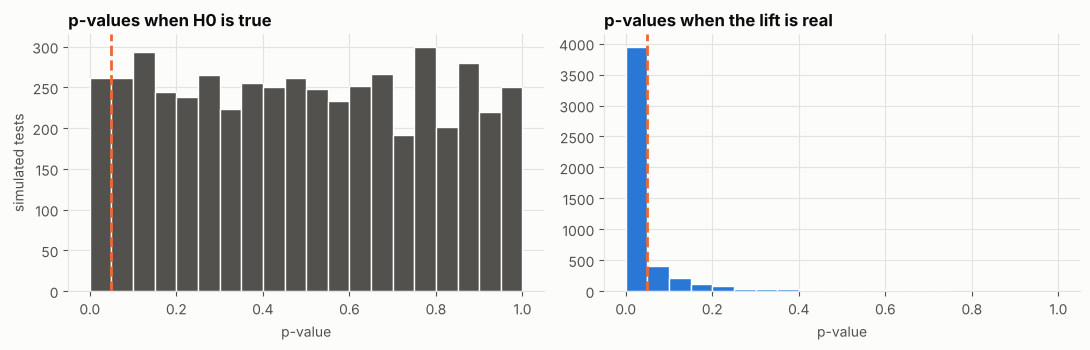

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
bins = np.linspace(0, 1, 21)
axes[0].hist(p_null, bins=bins, color=INK_2, edgecolor="white")
axes[0].axvline(ALPHA, color=PALETTE[1], linestyle="--")
axes[0].set(title="p-values when H0 is true", xlabel="p-value", ylabel="simulated tests")
axes[1].hist(p_alt, bins=bins, color=PALETTE[0], edgecolor="white")
axes[1].axvline(ALPHA, color=PALETTE[1], linestyle="--")
axes[1].set(title="p-values when the lift is real", xlabel="p-value")
fig.tight_layout()
save(fig, "ab_test_pvalues.png");

Under H0 the p-values are spread evenly from 0 to 1, which is exactly why 5% of them fall under 0.05. When the effect is real they pile up near zero. Peeking takes many small chances to catch a lucky dip, and those chances add up. If someone needs to look early, the fix is a sequential design that spends alpha across the looks, decided before the test starts.